# The value function, the current model, and comfort

Three topics:

1. **The value function $V(a, b)$**: what it is, the data behind it, and how it is
   estimated (raw rates, a logistic fit, shrinkage, a monotone projection).
2. **The current model** (`floored_overpromise_listener`): how it picks a clue and a
   number, what each of its parts is trained on, and where $\lambda$ enters.
3. **Comfort**: the measure of how clearly a spymaster's clues point at their number,
   and the table of comfort against win rate for every model in the comfort arena.

**Terms used throughout.**

- A **position** is the score $(a, b)$: the side about to give a clue has $a$ of its
  own words left, the other side $b$. Each side starts with 9 or 8.
- A **turn** is one clue with a number $k$, then the guesser's picks until it stops,
  picks a word that is not its own, or has made $k$ picks.
- The **incumbent** is `assoc_profile_listener`: the expected-words spymaster (own words
  found minus costs 0.2 / 1 / 10 for neutral / opponent / assassin words) with the
  association-profile listener. It is the fixed opponent in every win rate below.
- The **comfort arena** is 100 held-out boards, each played twice with the seats swapped,
  so 200 games per model. gpt-oss-120b guesses for both sides in two calls. First it
  sorts the board, without the number, into the words the clue clearly points at (the
  "guess" set) and the rest. Then it ranks only the guess set, with the number. It picks
  down that ranking and stops at a wrong word, after $k$ picks, or when the set runs
  out. It never takes the bonus $k+1$-th guess.

Everything is read from stored files: `cache/win_value_margin.npz`,
`cache/report/listener_accuracy.csv`,
`cache/report/comfort_frontier_holdout_v1_gptoss_subset_guess.json`. **The notebook
makes no API calls.**

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path("..").resolve()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts" / "data")]
from codenames.win_value import WinValue

D = np.load(ROOT / "cache" / "win_value_margin.npz")
n, w, prior, V = D["n"], D["wins"], D["prior"], D["V"]
idx = pd.Index(range(1, 10), name="a \\ b")

def grid(T, fmt="{:.3f}"):
    df = pd.DataFrame(T[1:, 1:], index=idx, columns=range(1, 10))
    return df.style.format(lambda x: "–" if pd.isna(x) else fmt.format(x))

## 1. The value function $V(a, b)$

### What it is

$$V(a, b) = P(\text{the side to move wins} \mid \text{it has } a \text{ own words left,
the other side has } b).$$

It sees only the score, not which words are left. It is estimated from 10,266
recorded games in which the incumbent's spymaster (or a variant differing only in a
cost setting) played both sides, with gpt-oss guessing. So $V$ is the incumbent's
value: the chance of winning from $(a, b)$ if both sides play like the incumbent from
then on. The model in section 2 chooses each clue to maximise $V$ after the turn,
which is one step of policy iteration: improve this turn, and assume the incumbent's
play afterwards.

### The data

Every game contributes one data point to each position it reaches at the start of a
turn: the cell $(a, b)$ of the side to move, and whether that side won. Let $n_{ab}$ be
the number of such data points and $w_{ab}$ the number won. All 10,266 games start at
$(9, 8)$.

In [2]:
print(f"{int(n.sum()):,} data points from {int(n[9, 8]):,} games")
grid(n.astype(float), "{:,.0f}")

86,287 data points from 10,266 games


,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,"3,886","2,334",941,477,104,26,4,7,0
2,"3,626","3,079","2,005",847,339,84,28,8,0
3,"2,481","3,035","2,631","1,653",649,186,103,14,6
4,"1,255","2,024","2,716","2,216","1,419",641,172,28,13
5,499,"1,194","2,147","2,440","2,049","1,436",370,72,4
6,141,487,"1,235","1,958","2,611","1,903",648,102,0
7,57,171,317,942,"1,847","2,340","1,416",808,130
8,9,31,89,254,"1,327","2,861","3,863",762,194
9,0,13,16,16,91,126,8,"10,266",0


**Reading.** The data lie along the diagonal and below it. Games stay close, and
positions where the side to move is behind ($b < a$) fill up late in games. The corners
are nearly empty: $(9, 1)$, $(1, 9)$, $(2, 9)$ and $(6, 9)$ have no games, and $(8, 1)$,
$(1, 7)$ and $(9, 7)$ fewer than 10. $(9, 9)$ cannot occur.

### Step 1: the raw rate

The direct estimate is the proportion won in each cell,
$$\hat p_{ab} = \frac{w_{ab}}{n_{ab}}.$$

In [3]:
grid(np.where(n > 0, w / np.maximum(n, 1), np.nan))

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.965,0.991,0.991,0.994,1.000,1.000,1.000,1.000,–
2,0.186,0.791,0.949,0.980,0.988,0.988,0.929,1.000,–
3,0.023,0.360,0.717,0.842,0.920,0.984,0.932,1.000,0.167
4,0.012,0.142,0.376,0.696,0.812,0.850,0.965,1.000,0.615
5,0.016,0.061,0.252,0.453,0.661,0.752,0.830,0.861,1.000
6,0.000,0.049,0.155,0.289,0.452,0.645,0.730,0.863,–
7,0.018,0.018,0.104,0.171,0.311,0.473,0.614,0.679,0.692
8,0.000,0.000,0.067,0.110,0.297,0.398,0.544,0.639,0.639
9,–,0.385,0.312,0.125,0.176,0.476,0.250,0.478,–


**Reading.** Where data are dense the raw rate is all that is needed: $(4, 4)$ is
$1{,}542 / 2{,}216 = 0.696$. In thin cells it is noise. $(9, 2)$ is 0.385 on 13 games,
which would say that a side with 9 words against 2 wins more often than one with 8
against 2 (0.000 on 31 games). $(3, 9)$ is 0.167 on 6 games, against 0.92–1.00 for every
neighbour. A spymaster scored against these numbers could prefer finding *fewer* of its
own words.

### Step 2: a smooth logistic fit

Next we fit one smooth surface to the whole table. The log-odds of winning are a
quadratic in the score plus two terms that let the very end of the game bend sharply:
$$\operatorname{logit} \pi_{ab} = \theta^\top x_{ab}, \qquad
x_{ab} = \left(1,\ a,\ b,\ a^2,\ b^2,\ ab,\ \tfrac{1}{a},\ \tfrac{1}{b}\right).$$
The eight $\theta$'s are fitted by binomial maximum likelihood over the cells with data,
that is, by minimising the cross-entropy
$$L(\theta) = -\sum_{a, b} \Big[ w_{ab} \log \sigma(\theta^\top x_{ab})
+ (n_{ab} - w_{ab}) \log\big(1 - \sigma(\theta^\top x_{ab})\big) \Big].$$
This is the same $\theta$ as a logistic regression with one row per data point. Each
cell therefore weighs in proportion to $n_{ab}$. The loss is convex, and L-BFGS finds
its minimum. There is no regularisation; eight parameters is the smoothing.

In [4]:
grid(prior)

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.961,0.997,0.999,1.000,1.000,1.000,1.000,1.000,1.000
2,0.188,0.786,0.939,0.977,0.989,0.994,0.996,0.997,0.998
3,0.033,0.354,0.697,0.863,0.931,0.961,0.974,0.981,0.984
4,0.011,0.145,0.415,0.661,0.808,0.884,0.922,0.941,0.949
5,0.005,0.068,0.233,0.455,0.643,0.765,0.834,0.872,0.889
6,0.002,0.036,0.136,0.301,0.482,0.627,0.723,0.779,0.806
7,0.001,0.022,0.085,0.203,0.355,0.498,0.606,0.675,0.711
8,0.001,0.014,0.057,0.143,0.264,0.394,0.502,0.576,0.616
9,0.001,0.010,0.041,0.106,0.204,0.316,0.418,0.492,0.534


**Reading.** The fit is smooth and monotone everywhere, including the empty corners.
It misses dense cells by a few points, because eight parameters cannot bend everywhere.
For example, $(8, 8)$ is 0.576 in the fit and 0.639 in 762 games.

### Step 3: shrinkage of each cell toward the fit

Thus the raw rate is right where data are dense and useless where they are thin, and the
fit is the reverse. Shrinkage takes each where it is reliable. Each cell is treated as
if $m = 20$ extra games had been played at the fit's rate:
$$\tilde V_{ab} = \frac{w_{ab} + m\, \pi_{ab}}{n_{ab} + m}
= (1 - \alpha_{ab})\, \hat p_{ab} + \alpha_{ab}\, \pi_{ab},
\qquad \alpha_{ab} = \frac{m}{n_{ab} + m}.$$
This is the posterior mean of a Beta prior centred on the fit with $m$ pseudo-games: an
empirical-Bayes estimate. The weight on the fit is negligible in a cell with thousands of
games and dominant in a cell with a handful.

In [5]:
shrunk = (w + 20 * prior) / (n + 20)
rows = []
for a, b in [(9, 8), (4, 4), (8, 8), (8, 9), (8, 2), (9, 2), (3, 9)]:
    rows.append({"(a, b)": f"({a}, {b})", "games": int(n[a, b]),
                 "raw rate": w[a, b] / n[a, b] if n[a, b] else np.nan, "fit": prior[a, b],
                 "weight on fit": 20 / (n[a, b] + 20), "shrunk": shrunk[a, b], "final V": V[a, b]})
pd.DataFrame(rows).set_index("(a, b)").style.format(
    {"raw rate": "{:.3f}", "fit": "{:.3f}", "weight on fit": "{:.1%}", "shrunk": "{:.3f}", "final V": "{:.3f}"})

,games,raw rate,fit,weight on fit,shrunk,final V
"(a, b)",,,,,,
"(9, 8)",10266,0.478,0.492,0.2%,0.478,0.478
"(4, 4)",2216,0.696,0.661,0.9%,0.696,0.696
"(8, 8)",762,0.639,0.576,2.6%,0.637,0.631
"(8, 9)",194,0.639,0.616,9.3%,0.637,0.651
"(8, 2)",31,0.000,0.014,39.2%,0.006,0.030
"(9, 2)",13,0.385,0.010,60.6%,0.158,0.028
"(3, 9)",6,0.167,0.984,76.9%,0.795,0.968


### Step 4: a monotone projection with a minimum step

After shrinkage a few cells can still be out of order. The true $V$ must fall as the
mover's own words left rise, and rise as the other side's rise:
$$V(a+1, b) \le V(a, b), \qquad V(a, b+1) \ge V(a, b).$$
So $\tilde V$ is projected onto the nearest table with that order, in least squares
weighted by $n_{ab} + m$. This is two-dimensional isotonic regression, computed by
alternating projections onto the row and column orders (Dykstra's algorithm).

A plain projection pools neighbouring cells into exact ties. At the opening it gave
$V(8, 9) = V(8, 8) = 0.637$, so the first team's first word looked worth nothing. To
prevent that, the projection is applied to $\tilde V - c\,\pi$ and $c\,\pi$ is added back,
with $c = 0.5$:
$$V = \Pi_{\text{monotone}}\big(\tilde V - c\,\pi\big) + c\,\pi.$$
Every step of $V$ is then at least half the fit's step at that point. The fit is
strictly monotone, so $V$ has no ties. Dense cells, whose own steps are larger, are
unchanged.

In [6]:
grid(V)

,1,2,3,4,5,6,7,8,9
a \ b,,,,,,,,,
1,0.965,0.991,0.992,0.994,1.000,1.000,1.000,1.000,1.000
2,0.186,0.791,0.949,0.979,0.986,0.988,0.989,0.998,0.998
3,0.024,0.360,0.717,0.842,0.920,0.956,0.963,0.966,0.968
4,0.013,0.142,0.376,0.696,0.812,0.851,0.937,0.946,0.951
5,0.010,0.062,0.252,0.453,0.661,0.752,0.830,0.878,0.908
6,0.005,0.046,0.155,0.289,0.453,0.645,0.730,0.832,0.845
7,0.004,0.034,0.103,0.172,0.324,0.473,0.614,0.681,0.699
8,0.001,0.030,0.078,0.121,0.279,0.403,0.544,0.631,0.651
9,0.001,0.028,0.070,0.103,0.181,0.364,0.415,0.478,0.534


**Reading.** In the dense band, $V$ is the raw rate to three decimals. The corners
follow the fit and the order constraint: $(3, 9)$ goes 0.167 → 0.795 (shrunk) → 0.968
(projected), because $V(3, 9)$ cannot sit below $V(3, 8) = 0.966$. The first row is
close to 1 (one word left, and the opponent needs more). The first column is close to 0
(the opponent needs one word and moves next) except at $(1, 1)$.

### What one more word is worth: `one_word`

Many decisions in section 2 use $V$ through one quantity: the value, in win
probability, of ending this turn with one own word found rather than none. When our
turn ends with $\ell$ own words left, the opponent moves at $(b, \ell)$, so our chance
is $1 - V(b, \ell)$. Thus
$$\text{one\_word}(a, b) = \big[1 - V(b, a-1)\big] - \big[1 - V(b, a)\big]
= V(b, a) - V(b, a-1),$$
with $1 - V(b, 0) = 1$, since finding our last word wins.

In [7]:
val = WinValue(ROOT / "cache" / "win_value_margin.npz")
pts = [(9, 8), (8, 9), (6, 6), (5, 4), (4, 4), (4, 2), (5, 2), (4, 1), (2, 2), (1, 4)]
pd.DataFrame({"one_word": [val.one_word(a, b) for a, b in pts]},
             index=pd.Index([f"({a}, {b})" for a, b in pts], name="(a, b)")).style.format("{:.3f}")

,one_word
"(a, b)",
"(9, 8)",0.020
"(8, 9)",0.064
"(6, 6)",0.193
"(5, 4)",0.116
"(4, 4)",0.320
"(4, 2)",0.031
"(5, 2)",0.006
"(4, 1)",0.002
"(2, 2)",0.605


**Reading.** A word is worth most in close games, and more the nearer the end ($(6, 6)$:
0.19; $(4, 4)$: 0.32; $(2, 2)$: 0.61). It is worth least where one word cannot change the
outcome. Ahead and near the end, the game is nearly won
anyway; behind by two or more against an opponent on its last words, it is nearly lost
anyway ($(4, 1)$: 0.002; $(5, 2)$: 0.006). At the opening it is 0.020, and that number
comes from the margin, not the data: the raw rates of $(8, 9)$ and $(8, 8)$ tie at 0.639,
so the step between them is half the fit's step.

### A robustness check: weighting cells by $\sqrt{n}$

The data points are not independent. One game passes through many cells, and all of
them share its outcome, so long games count more often than short ones. As a check,
the fit was redone with each cell weighted by $\sqrt{n_{ab}}$ instead of $n_{ab}$, which
gives thin cells relatively more say.

In [8]:
from build_win_value import logistic_fit, monotone_with_margin

def build(pi):
    T = (w + 20 * pi) / (n + 20)
    T[1:, 1:] = monotone_with_margin(T[1:, 1:].copy(), n[1:, 1:] + 20, pi[1:, 1:], 0.5)
    T[0, :], T[:, 0] = 1.0, 0.0
    return T

assert np.allclose(logistic_fit(n, w), prior) and np.allclose(build(prior)[1:, 1:], V[1:, 1:])
s = np.sqrt(n)
prior_sqrt = logistic_fit(np.where(n > 0, s, 0), np.where(n > 0, w / np.maximum(s, 1), 0))
V_sqrt = build(prior_sqrt)
rate = np.where(n > 0, w / np.maximum(n, 1), np.nan)
has = n[1:, 1:] > 0
out = {}
for name, pi, T in (("weight n (used)", prior, V), ("weight sqrt(n)", prior_sqrt, V_sqrt)):
    err = np.abs(pi - rate)[1:, 1:][has]
    nn = n[1:, 1:][has]
    out[name] = {"fit error, game-weighted": np.average(err, weights=nn),
                 "fit error, cells with 20-200 games": err[(nn >= 20) & (nn < 200)].mean(),
                 "opening one_word": V[8, 9] - V[8, 8] if T is V else T[8, 9] - T[8, 8]}
d = np.abs(V_sqrt - V)[1:, 1:]
print(f"game-weighted mean |change in V| {(d * n[1:, 1:]).sum() / n.sum():.4f}; largest {d.max():.3f} at "
      f"{tuple(int(i) + 1 for i in np.unravel_index(d.argmax(), d.shape))}")
pd.DataFrame(out).T.style.format("{:.4f}")

game-weighted mean |change in V| 0.0003; largest 0.040 at (5, 9)


,"fit error, game-weighted","fit error, cells with 20-200 games",opening one_word
weight n (used),0.0165,0.0322,0.0202
weight sqrt(n),0.0216,0.0385,0.0103


**Reading.** The final $V$ hardly moves (game-weighted mean change 0.0003). The only visible
changes are in the column where the other side still has 9 words, at cells with a few
games. The $\sqrt{n}$ fit is worse even on the mid-sized cells it was meant to help: eight
parameters cannot fit everywhere, and extra weight on noisy cells pulls the fit away from
the dense ones without matching the thin ones better. The one number that changes is the
opening's one_word (0.020 → 0.010), which, as above, comes from the fit's shape and not
from the data. $\sqrt{n}$ also does not address the dependence: it is *across* cells
(one game, many cells), while within a cell each game appears at most once.

## 2. The current model: P(win) with a floored overpromise charge

`floored_overpromise_listener` (λ = 1, floor 0.05). On every turn it does three things:

1. **Shortlist.** A cheap embedding model scores all ~11,000 legal clues in the pool
   (words at or below the 10th rarity percentile) by expected own words minus costs, and
   keeps the best 200.
2. **Predict the turn.** For each shortlisted clue, the **STOP listener** gives, at each
   pick, a probability for every word left and for STOP.
3. **Value it.** For each number $k = 1, \dots, \min(a, 4)$, compute the probability of
   winning after the turn under the STOP listener, minus a charge for each promised word
   the guesser is predicted not to attempt. Give the clue and number with the highest value.

### 2.1 The STOP listener

**What it predicts.** At pick $j$ of a turn, with the words $F$ already found, the
guesser's next action is a softmax over the words left and STOP:
$$P(x \mid j) = \frac{e^{s_j(x)}}{\sum_{y \notin F} e^{s_j(y)} + e^{s_j(\text{STOP})}},$$
where $s_j(x)$ is a LightGBM booster's score for word $x$ at pick $j$. A word's score
depends on the clue, the word, the board and the pick number $j$, not on which words were
found. STOP's score depends only on the pick number and clue-level features: how far the
best word leads, how many words look like candidates, and the clue's association
profile. So STOP has an absolute level against the words, which a ranking cannot provide.

**Features.** The incumbent's listener's 67 columns (embedding similarities in several
spaces, WordNet is-a, ConceptNet relations, gpt-oss free associations, word norms,
spelling, ...) without the number $k$, plus the pick number $j$ and an is-STOP flag: 68.

**Training data.** These come from 18,687 generated positions on boards of the 250
training words:
- a random number of words already revealed, so positions span the whole game;
- a clue drawn from the same pool the spymaster searches. 40% are aimed at the side's own
  words, 20% at the opponent's, 10% at the assassin, 10% at neutrals and 20% are random.
  Bad clues are included on purpose, because the search scores thousands of bad clues
  every turn.

For each position gpt-oss was asked, *without the number*, which board words the clue
clearly points at (the "guess" set; 1.84 words on average, 10% empty). The set is put in
order by gpt-oss's stored ranking of the same position. One choice event per pick:
- pick $j = 1, \dots, |S|$: the target is the $j$-th word of $S$, chosen among the words
  not yet picked and STOP;
- pick $|S| + 1$: the target is STOP.

**Loss.** The conditional-logit (group softmax) cross-entropy, with the events weighted
equally:
$$L = -\sum_{\text{events } e} \log P(t_e \mid j_e).$$
LightGBM is given its gradient $p - y$ and Hessian $p(1 - p)$ per group, and training is
early-stopped on McFadden $R^2$ on a validation split by board.

**Fit.** On 2,802 validation positions: $R^2 = 0.481$ (pick 1: 0.603; pick 2: 0.430; pick
3: 0.334; pick 4: 0.493). When the guesser did stop, the model gave STOP 0.56 on average;
when it went on, 0.24. Here
$$R^2 = 1 - \frac{\sum_e -\log P(t_e)}{\sum_e \log |C_e|},$$
where $C_e$ is the set of options at event $e$ (words left plus STOP), so the
denominator is the loss of choosing uniformly at random.

**Why the strict "guess" set.** The comfort arena's guesser stops exactly when that set
runs out, and a listener trained on the looser "guess + stretch" set announced 4 on most
boards.

**The ranking listener.** The incumbent's booster, trained on gpt-oss's full rankings,
provides the feature columns and is used in the shortlist step. Its own predictions do
not enter this model's choice. Its accuracy, for reference (McFadden $R^2$ on picks the
model was not trained on):

In [9]:
acc = pd.read_csv(ROOT / "cache" / "report" / "listener_accuracy.csv")
sets = {"train": "train (in-sample)", "held-out words, generated": "held-out words, gpt-oss",
        "held-out words, generated, Sonnet 5.5": "held-out words, Sonnet 5.5"}
r = acc[(acc.group == "features") & acc.model.isin(["incumbent", "+ association profile"]) & acc.set.isin(sets)]
r = r.assign(set=r.set.map(sets), model=r.model.map({"incumbent": "first listener (Sept.)",
                                                     "+ association profile": "association profile (used)"}))
r.set_index(["set", "model"])[["events", "r2", "pick_1", "pick_2", "pick_3", "pick_4"]].style.format(
    {"r2": "{:.3f}", "pick_1": "{:.3f}", "pick_2": "{:.3f}", "pick_3": "{:.3f}", "pick_4": "{:.3f}"})

### 2.2 The value of a turn

Let the turn start at $(a, b)$ with number $k$, and let $\ell = a - |F|$ be our words left
after finding the set $F$. When our turn ends with $\ell > 0$, the opponent moves at
$(b, \ell)$, so our chance of winning is
$$u(\ell, b) = 1 - V(b, \ell), \qquad u(0, b) = 1.$$
The value of the turn from state $F$, with $j = |F|$ picks made, is an exact recursion over
which own words have been found:
$$W_k(F) = \begin{cases}
1 & \ell = 0 \text{ (we found our last word)}\\[2pt]
u(\ell, b) & j = k \text{ (the number is used up)}\\[2pt]
\displaystyle \sum_{i \in \text{own} \setminus F} P(i \mid j)\, W_k(F \cup \{i\})
+ \sum_{x \in \text{bad}} P(x \mid j)\, u_x(\ell)
+ P(\text{STOP} \mid j)\,\big[u(\ell, b) - c\,(k - j)\big] & \text{otherwise.}
\end{cases}$$
A wrong word ends the turn at a position that depends on what the word was:
$$u_x(\ell) = \begin{cases} u(\ell, b) & x \text{ neutral} \\ u(\ell, b - 1) \ (0 \text{ if } b = 1) & x \text{ opponent's} \\ 0 & x \text{ the assassin.} \end{cases}$$
The clue and number given are
$$(\text{clue}^*, k^*) = \arg\max_{\text{clue},\ k \le \min(a, 4)} W_k(\varnothing).$$

### 2.3 Where $\lambda$ enters: the overpromise charge

Without the charge ($c = 0$), the P(win) objective treats a larger number as nearly free:
the STOP listener says the guesser will stop when the clue's words run out, so promising 4
for a clue that points at 2 costs nothing in the model. But a human who reads 4 chases 4,
and the clue is uncomfortable. So each promised word the guesser is predicted *not to
attempt* (a STOP after $j < k$ picks) is charged $c$ per word:
$$c = \lambda \cdot \max\big(\text{one\_word}(a, b),\ \varphi\big), \qquad \lambda = 1,\ \varphi = 0.05.$$
- $\lambda$ is in words: $\lambda = 1$ means each broken promise costs as much as one own
  word is worth at this score. It is the knob between winning and comfort; λ = 0.5 and 1
  were run.
- one_word converts words into win probability at the current score, so a broken promise
  costs more where a word matters more.
- The floor $\varphi$: one_word is near 0 where one word cannot change the game, mostly two
  or more behind against an opponent close to winning. There the charge vanished, and the
  model gave all-in 4s with clues that did not connect four words. With the floor, every
  position where one_word > 0.05 is unchanged.

Wrong words are not charged: the guesser attempted them, and they are paid for through the
position they leave. A turn that ends after $k$ picks is not charged.

In [10]:
pts = [(9, 8), (8, 9), (6, 6), (4, 4), (4, 2), (5, 2), (4, 1), (2, 2)]
pd.DataFrame([{"(a, b)": f"({a}, {b})", "charge without the floor (= one_word)": val.one_word(a, b),
               "charge with floor 0.05": max(val.one_word(a, b), 0.05)} for a, b in pts]
             ).set_index("(a, b)").style.format("{:.3f}")

,charge without the floor (= one_word),charge with floor 0.05
"(a, b)",,
"(9, 8)",0.020,0.050
"(8, 9)",0.064,0.064
"(6, 6)",0.193,0.193
"(4, 4)",0.320,0.320
"(4, 2)",0.031,0.050
"(5, 2)",0.006,0.050
"(4, 1)",0.002,0.050
"(2, 2)",0.605,0.605


**Reading.** With $\lambda = 1$ the charge is one_word itself wherever one_word is above 0.05.
The floor binds at the opening (0.020 → 0.05) and in the hopeless positions (0.002–0.031 →
0.05). In a close middle game, such as $(4, 4)$ at 0.32, a broken promise costs a lot.

**Measured effect of the floor** (number given, 12 holdout boards per score, no API):
opponent on its last word $(4, 1)$: mean number 4.00 without the floor (10 of 12 boards
all-in 4s with unconnected clues) → 1.00 with it. Opening $(9, 8)$: 3.08 → 3.00. Level
or ahead: unchanged.

## 3. Comfort

### Definition

For a turn $t$ with number $k_t$, let $G_t$ be the arena guesser's own answer to its first
question: the board words the clue clearly points at, asked without the number (any colour).
The turn's comfort is the share of the number those words cover:
$$\text{comfort}_t = \frac{\min(|G_t|, k_t)}{k_t},$$
and a model's comfort is the mean over its turns, each position counted once (a pass can
repeat a position):
$$\text{comfort} = \frac{1}{T} \sum_{t=1}^{T} \text{comfort}_t.$$
It is 1 when every clue's clear words cover its number. A clue for 3 that clearly points at
one word scores 1/3.

**Why the stored answer and not how the turn ended.** A turn cut short by a wrong guess
never shows whether the clear set would have run out first, so turn outcomes would mix
misreadings into the measure. $G_t$ is exactly what the arena guesser acted on, and it is
stored for every turn, so comfort costs nothing to compute. As a check, on 11 models it
ranks them the same as a separate probe asking gpt-oss how many words it is sure of
(Spearman 0.97).

**Intervals.** Win rate is the share of a model's 200 games against the incumbent.
Both intervals are 95% bootstraps that resample boards, since a board's two games are
paired.

In [11]:
fr = json.loads((ROOT / "cache" / "report" / "comfort_frontier_holdout_v1_gptoss_subset_guess.json").read_text())
tab = pd.DataFrame(fr["rows"])
tab["win% (95% CI)"] = [f"{x:.1%} [{lo:.1%}, {hi:.1%}]" for x, (lo, hi) in zip(tab.win, tab.win_ci)]
tab["comfort (95% CI)"] = [f"{x:.3f} [{lo:.3f}, {hi:.3f}]" for x, (lo, hi) in zip(tab.comfort, tab.comfort_ci)]
front = set(fr.get("frontier", []))
tab["frontier"] = ["*" if i in front or nm in front else "" for i, nm in zip(tab.id, tab.name)]
tab.sort_values("comfort", ascending=False)[["name", "games", "turns", "win% (95% CI)", "comfort (95% CI)",
                                              "frontier"]].set_index("name")

,games,turns,win% (95% CI),comfort (95% CI),frontier
name,,,,,
"overpromise 1.0, strict",200,965,"45.5% [40.0%, 51.0%]","0.944 [0.934, 0.954]",*
"overpromise 0.5, strict",200,943,"52.0% [46.5%, 58.0%]","0.929 [0.919, 0.939]",*
"stop, strict",198,912,"47.5% [41.9%, 53.0%]","0.919 [0.907, 0.932]",
"floored margin V + overpromise 1.0, strict",200,934,"51.5% [46.0%, 57.5%]","0.912 [0.898, 0.924]",
"stop_net, strict",200,933,"45.0% [39.0%, 51.5%]","0.910 [0.894, 0.924]",
"margin V + overpromise 1.0, strict",200,938,"51.5% [46.0%, 57.0%]","0.883 [0.866, 0.901]",
"win_prob + overpromise 1.0, strict",200,941,"53.5% [48.5%, 59.0%]","0.873 [0.852, 0.892]",*
profile_temperature,200,942,"50.0% [45.5%, 54.5%]","0.869 [0.854, 0.886]",
"margin V + overpromise 0.5, strict",200,930,"51.0% [45.5%, 56.5%]","0.854 [0.832, 0.875]",


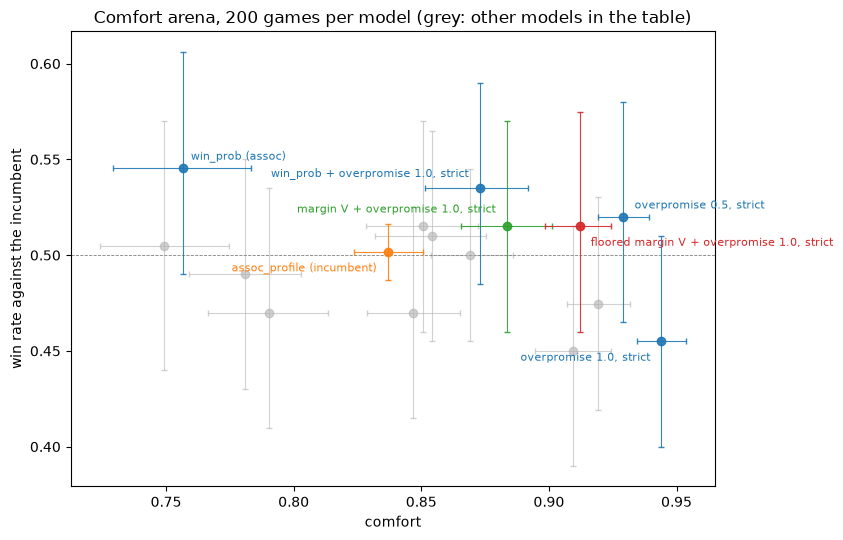

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
LABEL = {  # name: (colour, label offset in points, alignment)
    "floored margin V + overpromise 1.0, strict": ("C3", (8, -14), "left"),
    "margin V + overpromise 1.0, strict": ("C2", (-8, 10), "right"),
    "assoc_profile (incumbent)": ("C1", (-8, -14), "right"),
    "win_prob (assoc)": ("C0", (6, 6), "left"),
    "win_prob + overpromise 1.0, strict": ("C0", (-8, 8), "right"),
    "overpromise 0.5, strict": ("C0", (8, 6), "left"),
    "overpromise 1.0, strict": ("C0", (-8, -14), "right"),
}
for _, r in tab.iterrows():
    colour, off, ha = LABEL.get(r["name"], ("0.7", None, None))
    ax.errorbar(r.comfort, r.win, xerr=[[r.comfort - r.comfort_ci[0]], [r.comfort_ci[1] - r.comfort]],
                yerr=[[r.win - r.win_ci[0]], [r.win_ci[1] - r.win]], fmt="o", ms=6, color=colour,
                alpha=0.9 if off else 0.6, capsize=2, lw=0.8, zorder=3 if off else 2)
    if off:
        ax.annotate(r["name"], (r.comfort, r.win), fontsize=8, xytext=off, textcoords="offset points", ha=ha,
                    color=colour)
ax.axhline(0.5, color="grey", lw=0.6, ls="--")
ax.set_xlabel("comfort")
ax.set_ylabel("win rate against the incumbent")
ax.set_title("Comfort arena, 200 games per model (grey: other models in the table)")
plt.tight_layout()

**Reading.**
- The frontier (models no other model beats on both axes, starred) runs from win_prob
  (most wins, 54.5%, comfort 0.756) to overpromise 1.0 strict (most comfortable, 0.944,
  fewest wins, 45.5%). Pure P(win) asks for numbers
  the clue does not support; the charge buys comfort back.
- The floored model (red): 51.5% at 0.912, against 51.5% at 0.883 for the same model
  without the floor (green). Same wins, more comfort (the two comfort intervals barely touch), and
  a lower mean number (1.97 against 2.12). On boards won both ways it leads the incumbent
  18 to 15 (sign test p = 0.73).
- No win rate here differs significantly from 50%; the comfort differences are much
  larger than their intervals. Overpromise 0.5 strict (52.0%, 0.929) is ahead of the
  floored model on both, by less than either interval.

## Caveats

- **V is the incumbent's value against gpt-oss.** It says what a score is worth when both
  sides play like the incumbent and gpt-oss guesses. gpt-oss treats the number as a quota
  and ignores the score and the history (a separate probe), so V likely writes off a side
  whose opponent is on its last word more firmly than human play would.
- **V sees only the score.** It cannot tell a bad board from a bad score.
- **The data points behind V are dependent** (one game, many cells). The estimates are
  still per-cell rates, but the effective sample is smaller than the counts.
- **The opening's one_word comes from the fit's shape**, not from data, since the two cells
  that define it tie. The floor overrides it in the current model.
- **The STOP listener is trained on gpt-oss's "guess" sets** and evaluated in an arena
  whose guesser uses the same sets, so the arena favours it by construction. The
  question is whether those sets resemble what a person would guess.
- **Comfort is measured with the same model that guesses in the arena** (gpt-oss). It is
  a proxy for how clear a clue is to a human, not a measurement of it.
- **λ and the floor were set by hand** (λ = 1: the penalty that felt right in play on the
  local game page; φ = 0.05: of the floors tried, 0, 0.02, 0.05 and 0.1, the smallest that
  removed the all-in 4s on the check boards), not fitted.